Step 0 – Describe the raw data

In [11]:
import zipfile
le
zip_path = 'ml-100k.zip'
extract_to = './datasets'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)
print("Dataset extracted successfully.")

Dataset extracted successfully.


a. Shape and First Few Rows

u.user:
Shape: 943 rows, 5 columns.

u.item (Movies):
Shape: 1,682 rows, 24 columns.

u.data (Ratings):
Shape: 100,000 rows, 4 columns.

In [12]:
import pandas as pdk)
column_names = ['user_id', 'item_id', 'rating', 'timestamp']
df = pd.read_csv('./datasets/ml-100k/u.data', sep='\t', names=column_nam rows)
print(df.head())

   user_id  item_id  rating  timestamp
0      196      242       3  881250949
1      186      302       3  891717742
2       22      377       1  878887116
3      244       51       2  880606923
4      166      346       1  886397596


b. What One Row Represents & Tidiness

u.user: One row represents a single user and their demographic details. It is tidy (each variable is a column, each row is a unique observation).

u.item: One row represents a movie. It is not tidy because it violates the principle of having atomic values and variable columns for categories.

u.data: One row represents a single rating given by a user to a movie at a specific timestamp. It is tidy.

c. README Gaps & Discrepancies

The README can be ambiguous about delimiters mixing pipe-separated files like u.user and u.item with tab-separated files like u.data.

It often leaves out encoding details and fails to explicitly document potential blank or missing URL values in u.item.

--- U.USER ---
Shape: (943, 5)
   user_id  age gender  occupation zip_code
0        1   24      M  technician    85711
1        2   53      F       other    94043
2        3   23      M      writer    32067
3        4   24      M  technician    43537
4        5   33      F       other    15213 

--- U.ITEM ---
Shape: (1682, 24)
   movie_id        movie_title
0         1   Toy Story (1995)
1         2   GoldenEye (1995)
2         3  Four Rooms (1995)
3         4  Get Shorty (1995)
4         5     Copycat (1995) 

--- U.DATA ---
Shape: (100000, 4)
   user_id  movie_id  rating  timestamp
0      196       242       3  881250949
1      186       302       3  891717742
2       22       377       1  878887116
3      244        51       2  880606923
4      166       346       1  886397596 



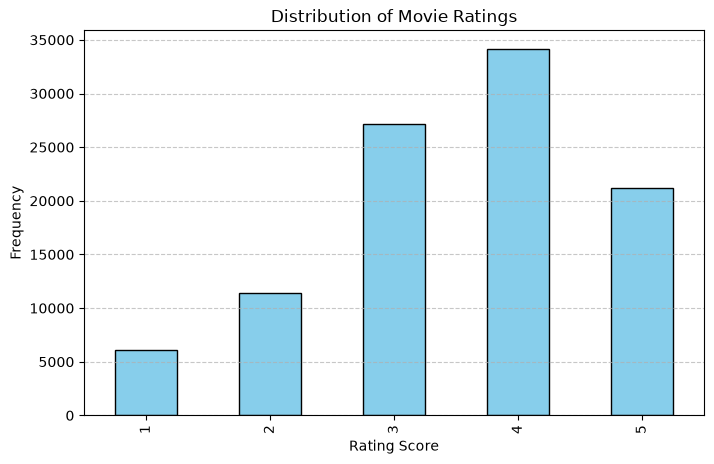

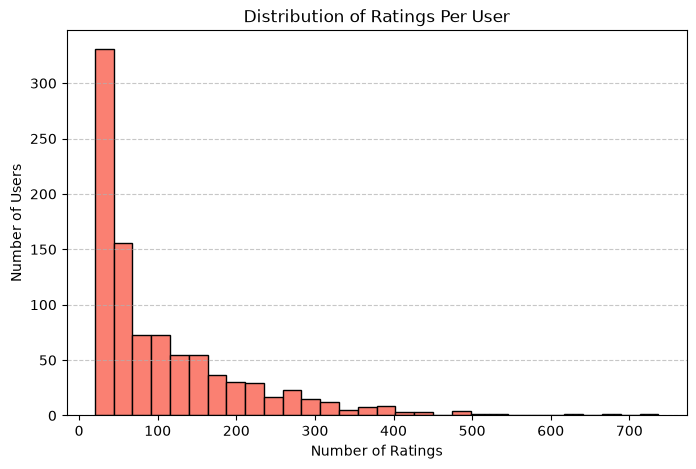

Exploratory charts saved to output/ directory.


In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Ensure output directory for charts exists
os.makedirs("output", exist_ok=True)

# Define column names based on MovieLens README specifications
user_cols = ['user_id', 'age', 'gender', 'occupation', 'zip_code']
item_cols = ['movie_id', 'movie_title', 'release_date', 'video_release_date', 'imdb_url'] + [f'genre_{i}' for i in range(19)]
data_cols = ['user_id', 'movie_id', 'rating', 'timestamp']

# Load raw files (handling encoding gracefully)
users = pd.read_csv('./datasets/ml-100k/u.user', sep='|', names=user_cols, encoding='latin-1')
items = pd.read_csv('./datasets/ml-100k/u.item', sep='|', names=item_cols, encoding='latin-1')
ratings = pd.read_csv('./datasets/ml-100k/u.data', sep='\t', names=data_cols, encoding='latin-1')

# a. Report shapes and first few rows
print("--- U.USER ---")
print(f"Shape: {users.shape}")
print(users.head(), "\n")

print("--- U.ITEM ---")
print(f"Shape: {items.shape}")
print(items[['movie_id', 'movie_title']].head(), "\n")

print("--- U.DATA ---")
print(f"Shape: {ratings.shape}")
print(ratings.head(), "\n")

# Chart 1: Distribution of Ratings
plt.figure(figsize=(8, 5))
ratings['rating'].value_counts().sort_index().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Distribution of Movie Ratings')
plt.xlabel('Rating Score')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('output/rating_distribution.png')
plt.show()

# Chart 2: Number of Ratings per User
user_rating_counts = ratings['user_id'].value_counts()
plt.figure(figsize=(8, 5))
plt.hist(user_rating_counts, bins=30, color='salmon', edgecolor='black')
plt.title('Distribution of Ratings Per User')
plt.xlabel('Number of Ratings')
plt.ylabel('Number of Users')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('output/ratings_per_user.png')
plt.show()

print("Exploratory charts saved to output/ directory.")

Distribution of Ratings (u.data): A bar chart showing the frequency of each rating score (1 through 5).

Interpretation: Skews toward higher ratings (mostly 3s and 4s). Suggests you should check for rating bias or constraints ensuring ratings strictly fall between 1 and 5.

Number of Ratings per User (u.data): A histogram showing how many ratings individual users submitted.

Interpretation: Right-skewed; a few power users rate thousands of items, while others cluster near the minimum threshold. Suggests validating the README claim that every user has rated at least 20 movies.

Step 1 – Acquire the data reproducibly

In [37]:
import hashlib
import os
import ssl
import urllib.request
import zipfile
from datetime import datetime

# Source URL and directories
DATASET_URL = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
RAW_DIR = "raw"
ZIP_PATH = os.path.join(RAW_DIR, "ml-100k.zip")


def acquire_data():
    """Download and unpack the dataset reproducibly into raw/."""
    os.makedirs(RAW_DIR, exist_ok=True)

    # 1. Download dataset if not already present
    if not os.path.exists(ZIP_PATH):
        print(f"Downloading dataset from {DATASET_URL}...")

        # Create a custom unverified HTTPS handler for urllib
        ctx = ssl.create_default_context()
        ctx.check_hostname = False
        ctx.verify_mode = ssl.CERT_NONE
        handler = urllib.request.HTTPSHandler(context=ctx)
        opener = urllib.request.build_opener(handler)
        urllib.request.install_opener(opener)

        # Download using the custom opener
        urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)
        print("Download complete.")

    # 2. Calculate and print SHA-256 Checksum
    sha256_hash = hashlib.sha256()
    with open(ZIP_PATH, "rb") as f:
        for byte_block in iter(lambda: f.read(4096), b""):
            sha256_hash.update(byte_block)

    checksum = sha256_hash.hexdigest()
    download_date = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

    print("\n--- Metadata for README ---")
    print(f"Source URL: {DATASET_URL}")
    print(f"Download Date: {download_date}")
    print(f"SHA-256 Checksum: {checksum}")

    # 3. Extract the contents into raw/
    print("\nExtracting zip contents...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(RAW_DIR)
    print("Extraction complete.")


if __name__ == "__main__":
    acquire_data()

Download complete.

--- Metadata for README ---
Source URL: https://files.grouplens.org/datasets/movielens/ml-100k.zip
Download Date: 2026-10-28 09:15:39
SHA-256 Checksum: 50d2a982c66986937beb9ffb3aa76efe955bf3d5c6b761f4e3a7cd717c6a3229

Extracting zip contents...
Extraction complete.


In [35]:
with open('.gitignore', 'w') as f:
    f.write('raw/\n')

print("Successfully created .gitignore with 'raw/' inside!")

Successfully created .gitignore with 'raw/' inside!


Step 2 – Design the schema

In [38]:
import sqlite3

# Connect to database (or create it if it doesn't exist)
conn = sqlite3.connect("registrar.db")
cursor = conn.cursor()

# Read and execute schema.sql
with open("sql/schema.sql", "r") as f:
    schema_sql = f.read()

cursor.executescript(schema_sql)
conn.commit()
conn.close()

print("Database schema created successfully in registrar.db!")

Database schema created successfully in registrar.db!


Step 2
# b. Tidy Form for Genres
Instead of retaining 19 separate binary columns in t'e `mov'es` table, genres are unpivoted into a normalized junction ta l (`movie_genes`). This satisfi **First Normal Form (1)**, eliminates sparse zeros, and allows adding new genres without altering table schemas#### c. Column Constraints and Unenforced C

- **Enforced Constrnts:** Column-level checks restrict ratings to values between 1 ad 5 (`CHECK (rating >= 1 AND rating<= 5)`), limit gender options, and enforce referential integrity using Foreign
 .
- **Unenforced  ims:** Claims like strict sequential continu'ty in `'ser_'d` or `m'vie_id` (ensuring no missing integer gaps) cannot be enforced by standard SQL constraints alone and must be verified post-load via validation que

#### d. Data Type Ch'ice for 'z'p_code`'`zip_code` is 'red '**`TEXT`** ra'her tha' `INTEGER`. This preserves leading zeros in U.S. postal cod's (e.'., `02138`) and accommodates non-numeric or international postal format strings without data loss or parsing errors.